# Lab Assignment 9 — Fall Detection with a 3D CNN (UR Fall Detection Dataset)

**Course:** CSET343 – AI in Healthcare  |  **Program:** B.Tech (Year 4, Sem VII)

## Objective
Design and evaluate a **3D Convolutional Neural Network (3D CNN)** that classifies a video clip as **fall** or **non-fall (ADL – Activities of Daily Living)**, to support elderly-care / hospital monitoring.

## Notebook roadmap
| Task | Section |
|---|---|
| **Task 1** | Data acquisition, discovery & visual exploration (fall vs. ADL) |
| **Task 2** | Corruption check, frame extraction, resize, normalisation, RGB, 4-D tensors, augmentation, class imbalance, 70/15/15 split |
| **Task 3** | 3D CNN baseline, training, Accuracy / Precision / Recall / F1 / AUROC, confusion matrix, ROC, error analysis (camera view, occlusion, motion blur) |

## How to run
1. Run on a GPU runtime if possible (Colab / Kaggle / local CUDA). CPU works but is slow.
2. The dataset is downloaded automatically with `kagglehub` (needs internet; if Kaggle asks for credentials, see Section 1). You can also download it manually and set `DATA_ROOT`.
3. Run all cells top to bottom.

> **Design notes (read once):**
> * Labels: `fall = 1` (positive class), `ADL / non-fall = 0`.
> * Only the **RGB** modality is used (depth and accelerometer files are ignored automatically).
> * The same physical fall is often recorded by **two cameras** (cam0 and cam1). To avoid **data leakage**, the train/val/test split is done **per event** (both views of one fall always land in the same split).

In [1]:
# Uncomment and run once if packages are missing
# %pip install -q kagglehub opencv-python scikit-learn matplotlib seaborn pandas tqdm torch torchvision

## 0. Setup & Configuration

In [2]:
import os, re, random, time, warnings, contextlib
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms.functional as TF

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, classification_report)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# ------------------------- Configuration -------------------------
SEED          = 42
N_FRAMES      = 16      # frames per clip fed to the network (try 32 for more temporal detail)
CACHE_FRAMES  = 64      # frames cached per video (uniformly sampled) -> source for temporal jittering
CACHE_SIZE    = 128     # cached spatial size (random-crop to CROP_SIZE during training)
CROP_SIZE     = 112     # final network input: 112 x 112
CAMERAS       = None    # None = use every RGB sequence found; or e.g. ["cam0"] for cam0 only
BATCH_SIZE    = 8
EPOCHS        = 40
LR            = 5e-4
WEIGHT_DECAY  = 1e-4
PATIENCE      = 12      # early-stopping patience (epochs)
USE_WEIGHTED_LOSS = True    # class imbalance: weighted BCE loss (pos_weight)
USE_OVERSAMPLING  = False   # class imbalance: oversample minority class (WeightedRandomSampler)

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

if torch.cuda.is_available():
    device = torch.device("cuda")
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
USE_AMP = device.type == "cuda"
print("Device:", device, "| mixed precision:", USE_AMP)

C:\Users\Apoorv Bagga\AppData\Roaming\Python\Python310\site-packages\torch\cuda\__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Device: cuda | mixed precision: True


# TASK 1 — Data Acquisition and Exploration

## 1.1 Download the dataset
The notebook uses `kagglehub`. If it asks for credentials, create a Kaggle API token (Kaggle → Settings → *Create New Token*) and either place `kaggle.json` in `~/.kaggle/` or set the `KAGGLE_USERNAME` / `KAGGLE_KEY` environment variables.

If you already downloaded/unzipped the data (or use any other mirror), set `DATA_ROOT = "path/to/folder"` below and skip the download.

In [3]:
DATA_ROOT = "UR_fall_detection_dataset_cam0_rgb"  

if DATA_ROOT is None:
    try:
        import kagglehub
        DATA_ROOT = kagglehub.dataset_download("shahliza27/ur-fall-detection-dataset")
    except Exception as e:
        print("Automatic download failed:", repr(e))
        print("-> Download manually from https://www.kaggle.com/datasets/shahliza27/ur-fall-detection-dataset,")
        print("   unzip it and set DATA_ROOT above.")

assert DATA_ROOT is not None and Path(DATA_ROOT).exists(), "Set DATA_ROOT to the dataset folder."
print("Dataset folder:", DATA_ROOT)

# quick look at the folder structure (2 levels deep)
root = Path(DATA_ROOT)
for p in sorted(root.iterdir())[:15]:
    print(" ", p.name, "/" if p.is_dir() else "")
    if p.is_dir():
        for q in sorted(p.iterdir())[:4]:
            print("     ", q.name)

Dataset folder: UR_fall_detection_dataset_cam0_rgb
  adl-01-cam0-rgb /
      adl-01-cam0-rgb-001.png
      adl-01-cam0-rgb-002.png
      adl-01-cam0-rgb-003.png
      adl-01-cam0-rgb-004.png
  adl-02-cam0-rgb /
      adl-02-cam0-rgb-001.png
      adl-02-cam0-rgb-002.png
      adl-02-cam0-rgb-003.png
      adl-02-cam0-rgb-004.png
  adl-03-cam0-rgb /
      adl-03-cam0-rgb-001.png
      adl-03-cam0-rgb-002.png
      adl-03-cam0-rgb-003.png
      adl-03-cam0-rgb-004.png
  adl-04-cam0-rgb /
      adl-04-cam0-rgb-001.png
      adl-04-cam0-rgb-002.png
      adl-04-cam0-rgb-003.png
      adl-04-cam0-rgb-004.png
  adl-05-cam0-rgb /
      adl-05-cam0-rgb-001.png
      adl-05-cam0-rgb-002.png
      adl-05-cam0-rgb-003.png
      adl-05-cam0-rgb-004.png
  adl-06-cam0-rgb /
      adl-06-cam0-rgb-001.png
      adl-06-cam0-rgb-002.png
      adl-06-cam0-rgb-003.png
      adl-06-cam0-rgb-004.png
  adl-07-cam0-rgb /
      adl-07-cam0-rgb-001.png
      adl-07-cam0-rgb-002.png
      adl-07-cam0-rgb-003.png

## 1.2 Discover RGB sequences and build a metadata table
Different Kaggle mirrors store URFD differently (original **PNG frame folders** such as `fall-01-cam0-rgb/`, or **video files** `.mp4/.avi`). The discovery code below handles both, ignores depth / accelerometer data, parses the label (`fall` / `adl`), event number and camera from the names, and removes duplicate copies.

In [4]:
VIDEO_EXT = {".mp4", ".avi", ".mov", ".mkv", ".wmv"}
IMG_EXT   = {".png", ".jpg", ".jpeg", ".bmp"}

def natural_key(s):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", str(s))]

def is_depth(name):
    n = name.lower()
    return ("depth" in n) or bool(re.search(r"[-_]d$", n))

def parse_meta(parts):
    """Parse (activity, event number, camera) from path components (deepest first)."""
    activity = num = None
    for part in reversed(parts):
        m = re.search(r"(fall|adl)[-_ ]?0*(\d+)", part.lower())
        if m:
            activity, num = m.group(1), int(m.group(2)); break
    if activity is None:
        return None
    cam = "unknown"
    for part in reversed(parts):
        m = re.search(r"cam[-_ ]?(\d)", part.lower())
        if m:
            cam = f"cam{m.group(1)}"; break
    return activity, num, cam

def discover(root):
    root = Path(root); rows = []
    for dirpath, _, filenames in os.walk(root):
        dp = Path(dirpath); rel = dp.relative_to(root).parts
        if any(is_depth(p) for p in rel):
            continue
        imgs = [f for f in filenames if Path(f).suffix.lower() in IMG_EXT]
        vids = [f for f in filenames if Path(f).suffix.lower() in VIDEO_EXT]
        if len(imgs) >= 8:                      # a folder of frames == one sequence
            meta = parse_meta(rel)
            if meta:
                rows.append(dict(path=str(dp), src="frames", meta=meta))
        for v in vids:                          # a single video file == one sequence
            stem = Path(v).stem
            if is_depth(stem):
                continue
            meta = parse_meta(rel + (stem,))
            if meta:
                rows.append(dict(path=str(dp / v), src="video", meta=meta))
    out = []
    for r in rows:
        activity, num, cam = r["meta"]
        out.append(dict(path=r["path"], src=r["src"], activity=activity, event_no=num, camera=cam,
                        label=int(activity == "fall"),
                        group=f"{activity}-{num:02d}",
                        sample_id=f"{activity}-{num:02d}-{cam}"))
    d = pd.DataFrame(out)
    if len(d):
        n0 = len(d)
        d = d.drop_duplicates("sample_id").sort_values(["label", "event_no", "camera"], ascending=[False, True, True])
        if len(d) < n0:
            print(f"Removed {n0 - len(d)} duplicate copies of the same sequence.")
    return d.reset_index(drop=True)

df = discover(DATA_ROOT)
if CAMERAS is not None:
    df = df[df.camera.isin(CAMERAS)].reset_index(drop=True)

if len(df) == 0:
    raise RuntimeError("No RGB sequences found. Check DATA_ROOT and the folder structure printed above "
                       "(names should contain 'fall-XX' / 'adl-XX').")
print(f"Found {len(df)} RGB sequences  |  falls: {(df.label==1).sum()}  |  ADL: {(df.label==0).sum()}")
print("Sequences per camera:\n", df.camera.value_counts().to_string())
df.head()

Found 70 RGB sequences  |  falls: 30  |  ADL: 40
Sequences per camera:
 camera
cam0    70


,path,src,activity,event_no,camera,label,group,sample_id
0,UR_fall_detection_dataset_cam0_rgb\fall-01-cam...,frames,fall,1,cam0,1,fall-01,fall-01-cam0
1,UR_fall_detection_dataset_cam0_rgb\fall-02-cam...,frames,fall,2,cam0,1,fall-02,fall-02-cam0
2,UR_fall_detection_dataset_cam0_rgb\fall-03-cam...,frames,fall,3,cam0,1,fall-03,fall-03-cam0
3,UR_fall_detection_dataset_cam0_rgb\fall-04-cam...,frames,fall,4,cam0,1,fall-04,fall-04-cam0
4,UR_fall_detection_dataset_cam0_rgb\fall-05-cam...,frames,fall,5,cam0,1,fall-05,fall-05-cam0


## 1.3 Basic statistics (frames per sequence, resolution)

         n_frames                                               
            count   mean   std   min    25%    50%    75%    max
activity                                                        
adl          40.0  223.5  79.0  70.0  180.0  232.5  271.2  400.0
fall         30.0   99.8  40.6  55.0   67.0   93.5  110.0  215.0

Resolutions found: {(640, 480): 70}


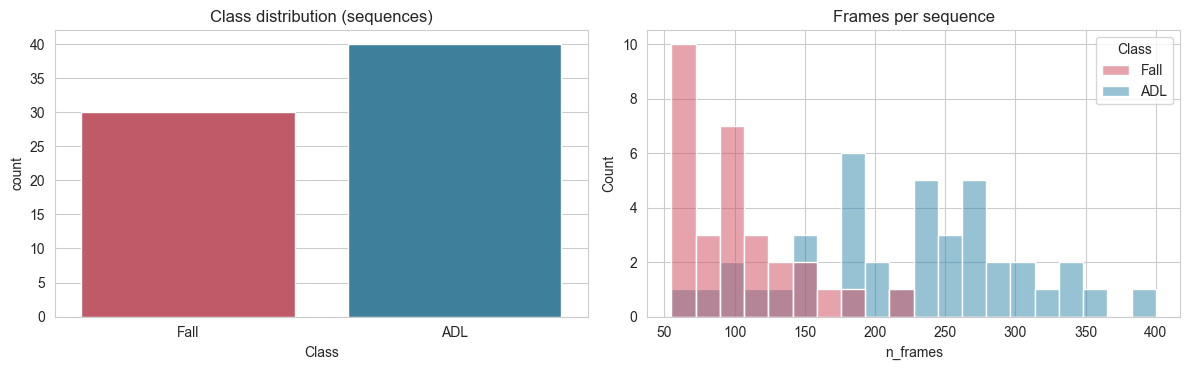

In [5]:
def _prep(img, size=None):
    """BGR/gray/BGRA (OpenCV) -> RGB uint8, optionally resized to size=(W, H)."""
    if img is None:
        raise IOError("unreadable frame")
    if img.ndim == 2:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    elif img.shape[2] == 4:
        img = cv2.cvtColor(img, cv2.COLOR_BGRA2RGB)
    else:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)          # ensure consistent RGB channels
    if img.dtype != np.uint8:
        img = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    if size is not None:
        img = cv2.resize(img, size, interpolation=cv2.INTER_AREA)
    return img

def list_frames(folder):
    return sorted([p for p in Path(folder).iterdir() if p.suffix.lower() in IMG_EXT],
                  key=lambda p: natural_key(p.name))

def read_sequence(rec, n_out, size=None):
    """Uniformly sample n_out frames from a sequence -> uint8 array (n_out, H, W, 3), RGB.
       size=(W, H) resizes every frame; None keeps original resolution."""
    if rec["src"] == "frames":
        files = list_frames(rec["path"])
        idx = np.linspace(0, len(files) - 1, n_out).round().astype(int)
        return np.stack([_prep(cv2.imread(str(files[i])), size) for i in idx])
    cap = cv2.VideoCapture(rec["path"]); frames = []
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        frames.append(_prep(fr, size))
    cap.release()
    if len(frames) == 0:
        raise IOError("no frames could be decoded")
    idx = np.linspace(0, len(frames) - 1, n_out).round().astype(int)
    return np.stack([frames[i] for i in idx])

def inspect_seq(rec):
    if rec["src"] == "frames":
        files = list_frames(rec["path"]); im = cv2.imread(str(files[0]))
        return len(files), im.shape[0], im.shape[1], np.nan
    cap = cv2.VideoCapture(rec["path"])
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); fps = cap.get(cv2.CAP_PROP_FPS)
    ok, im = cap.read(); cap.release()
    return n, (im.shape[0] if ok else np.nan), (im.shape[1] if ok else np.nan), fps

stats = [inspect_seq(r) for _, r in df.iterrows()]
df[["n_frames", "height", "width", "fps"]] = pd.DataFrame(stats, index=df.index)

print(df.groupby("activity")[["n_frames"]].describe().round(1).to_string())
print("\nResolutions found:", df.groupby(["width", "height"]).size().to_dict())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.countplot(data=df.assign(Class=df.label.map({1: "Fall", 0: "ADL"})), x="Class", hue="Class",
              palette={"Fall": "#d1495b", "ADL": "#2e86ab"}, ax=ax[0], legend=False)
ax[0].set_title("Class distribution (sequences)")
sns.histplot(data=df.assign(Class=df.label.map({1: "Fall", 0: "ADL"})), x="n_frames", hue="Class",
             bins=20, palette={"Fall": "#d1495b", "ADL": "#2e86ab"}, ax=ax[1])
ax[1].set_title("Frames per sequence")
plt.tight_layout(); plt.show()

## 1.4 Visual exploration: Fall vs. normal activity
Eight evenly spaced frames from one fall and one ADL sequence (original resolution).

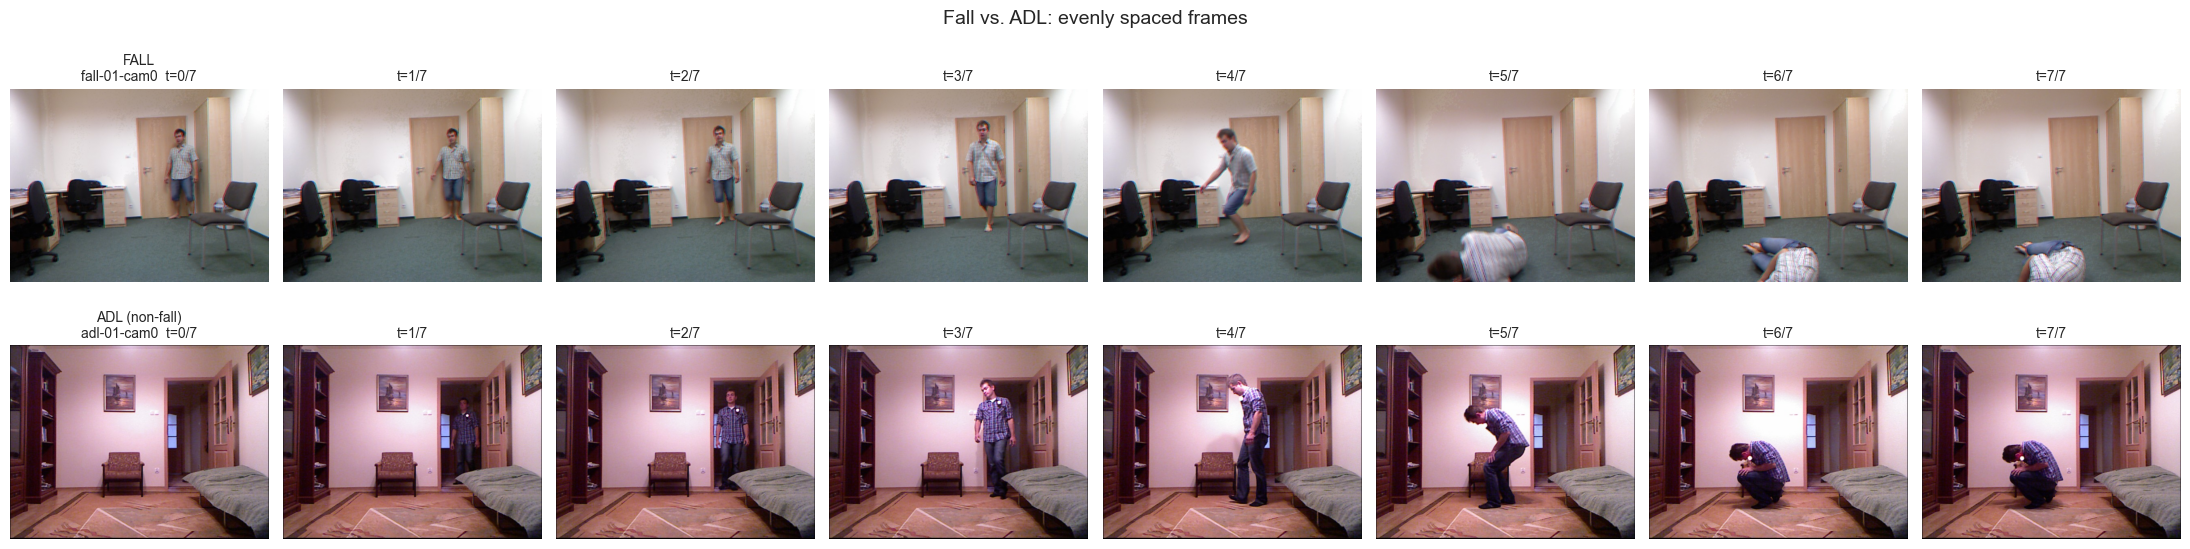

In [6]:
fig, axes = plt.subplots(2, 8, figsize=(22, 6))
for r, (lab, name) in enumerate([(1, "FALL"), (0, "ADL (non-fall)")]):
    pool = df[df.label == lab]
    rec = pool[pool.camera == "cam0"].iloc[0] if (pool.camera == "cam0").any() else pool.iloc[0]
    fr = read_sequence(rec, 8)
    for c in range(8):
        axes[r, c].imshow(fr[c]); axes[r, c].axis("off")
        axes[r, c].set_title(f"{name}\n{rec['sample_id']}  t={c}/7" if c == 0 else f"t={c}/7", fontsize=10)
plt.suptitle("Fall vs. ADL: evenly spaced frames", fontsize=14); plt.tight_layout(); plt.show()

**Visual differences (what the model has to learn)**

| | Fall | ADL / non-fall |
|---|---|---|
| **Motion** | A short, *fast* burst of vertical / downward body movement | Slow, regular motion (walking, sitting down, bending, picking something up) |
| **Posture change** | Upright → horizontal on the floor in about a second | Posture changes are gradual, or the person stays upright |
| **End state** | Person lies *motionless on the floor* after the burst | Person is upright, seated, or lying on furniture (bed / sofa) in a controlled way |
| **Hard look-alikes** | Falls behind furniture (occluded), slow slumps | Sitting down abruptly, crouching, lying down deliberately on a mattress or floor |

These look-alikes are exactly where we expect classification errors later (Task 3).

# TASK 2 — Data Preprocessing

## 2.1 Verify and remove corrupted files
Every sequence is fully decoded (all frames for folders, all frames for videos). A sequence is removed if any frame is unreadable or it has fewer than 8 frames.

In [ ]:
def verify_sequence(rec, min_frames=8):
    try:
        if rec["src"] == "frames":
            files = list_frames(rec["path"])
            if len(files) < min_frames:
                return False, f"only {len(files)} frames"
            for f in files:
                if cv2.imread(str(f)) is None:
                    return False, f"unreadable frame {f.name}"
        else:
            cap = cv2.VideoCapture(rec["path"])
            if not cap.isOpened():
                return False, "cannot open video"
            n = 0
            while True:
                ok, fr = cap.read()
                if not ok:
                    break
                if fr is None or fr.size == 0:
                    return False, "empty frame"
                n += 1
            cap.release()
            if n < min_frames:
                return False, f"only {n} decodable frames"
        return True, ""
    except Exception as e:
        return False, repr(e)

checks = [verify_sequence(r) for _, r in tqdm(df.iterrows(), total=len(df), desc="Verifying")]
df["ok"] = [c[0] for c in checks]; df["problem"] = [c[1] for c in checks]
bad = df[~df.ok]
print(f"Corrupted / unusable sequences: {len(bad)}")
if len(bad):
    print(bad[["sample_id", "problem"]].to_string(index=False))
df = df[df.ok].drop(columns=["ok", "problem"]).reset_index(drop=True)
print(f"Remaining sequences: {len(df)}  (falls={int((df.label==1).sum())}, ADL={int((df.label==0).sum())})")

Verifying:   0%|          | 0/70 [00:00<?, ?it/s]

## 2.2 Frame extraction, resizing, RGB conversion, stacking
For every video we uniformly sample **64 frames** across the whole sequence, convert to **RGB**, resize to **128×128** and stack into one `uint8` tensor of shape `(frames, H, W, C)`. This cache lives in RAM (≈ 3 MB per video).

During training a **16-frame clip** is drawn from these 64 frames (temporal jittering) and randomly cropped to **112×112**; during validation/testing the clip is a fixed uniform sample with a centre crop. Pixel values are scaled to **[0, 1]** when the clip is converted to a float tensor.

In [ ]:
cache = np.zeros((len(df), CACHE_FRAMES, CACHE_SIZE, CACHE_SIZE, 3), dtype=np.uint8)
failed = []
for i, rec in tqdm(df.iterrows(), total=len(df), desc="Extracting frames"):
    try:
        cache[i] = read_sequence(rec, CACHE_FRAMES, size=(CACHE_SIZE, CACHE_SIZE))
    except Exception as e:
        failed.append((i, repr(e)))

if failed:
    print("Dropping sequences that failed during extraction:", failed)
    keep = [i for i in range(len(df)) if i not in {f[0] for f in failed}]
    df = df.iloc[keep].reset_index(drop=True); cache = cache[keep]

print("Cached tensor shape (videos, frames, H, W, C):", cache.shape, "| dtype:", cache.dtype)
print(f"Memory: {cache.nbytes / 1e6:.0f} MB")

## 2.3 Motion profile — a quick sanity check of the extracted tensors
The mean absolute frame difference over time summarises how much movement happens in a video. Falls should show sharper bursts than ADL.

In [ ]:
def motion_profile(clip):
    """Mean absolute difference between consecutive frames. clip: (T,H,W,3) uint8 -> (T-1,)"""
    g = clip.astype(np.float32).mean(-1) / 255.0
    return np.abs(np.diff(g, axis=0)).mean(axis=(1, 2))

profiles = np.stack([motion_profile(cache[i]) for i in range(len(df))])
t = np.linspace(0, 1, profiles.shape[1])
fig, ax = plt.subplots(figsize=(10, 4))
for lab, col, name in [(1, "#d1495b", "Fall"), (0, "#2e86ab", "ADL")]:
    P = profiles[df.label.values == lab]
    for p in P:
        ax.plot(t, p, color=col, alpha=0.12)
    ax.plot(t, P.mean(0), color=col, lw=3, label=f"{name} (mean, n={len(P)})")
ax.set_xlabel("Normalised time in video"); ax.set_ylabel("Mean |frame difference|")
ax.set_title("Motion energy over time"); ax.legend(); plt.show()

## 2.4 Train / validation / test split (70 / 15 / 15)
* **Stratified** by class (each split contains falls and ADL).
* **Grouped by event** – both camera views of the same fall (`fall-07-cam0`, `fall-07-cam1`) always stay together, otherwise the model would be tested on a video it has effectively already seen.

In [ ]:
def group_stratified_split(d, ratios=(0.70, 0.15, 0.15), seed=SEED):
    rng = np.random.RandomState(seed)
    assign = {}
    for lab in sorted(d.label.unique()):
        groups = np.array(sorted(d[d.label == lab].group.unique())); rng.shuffle(groups)
        n = len(groups)
        n_va = max(1, int(round(n * ratios[1]))); n_te = max(1, int(round(n * ratios[2])))
        n_tr = n - n_va - n_te
        for g in groups[:n_tr]:             assign[g] = "train"
        for g in groups[n_tr:n_tr + n_va]:  assign[g] = "val"
        for g in groups[n_tr + n_va:]:      assign[g] = "test"
    return d.group.map(assign)

df["split"] = group_stratified_split(df)
tr_idx = df.index[df.split == "train"].values
va_idx = df.index[df.split == "val"].values
te_idx = df.index[df.split == "test"].values

# sanity: no event appears in two splits
assert df.groupby("group").split.nunique().max() == 1, "Leakage: an event is in more than one split"

summary = pd.crosstab(df.split, df.label.map({1: "Fall", 0: "ADL"}), margins=True).loc[["train", "val", "test", "All"]]
print(summary.to_string())
print(f"\nSequence share  ->  train {len(tr_idx)/len(df):.0%} | val {len(va_idx)/len(df):.0%} | test {len(te_idx)/len(df):.0%}")

## 2.5 Handling class imbalance
Two standard remedies are implemented and switchable in the configuration cell:
1. **Weighted loss** (`USE_WEIGHTED_LOSS=True`, default): `BCEWithLogitsLoss(pos_weight = #negatives / #positives)` computed on the *training* set only.
2. **Oversampling** (`USE_OVERSAMPLING=True`): a `WeightedRandomSampler` draws minority-class videos more often so each batch is balanced.

(Use one of them; using both would over-correct.)

In [ ]:
y_train = df.loc[tr_idx, "label"].values
n_pos, n_neg = int((y_train == 1).sum()), int((y_train == 0).sum())
pos_weight_value = n_neg / max(n_pos, 1)
print(f"Training set: {n_pos} fall vs {n_neg} ADL  ->  pos_weight = {pos_weight_value:.3f}")
print(f"Weighted loss: {USE_WEIGHTED_LOSS} | Oversampling: {USE_OVERSAMPLING}")

## 2.6 Dataset class with data augmentation
**Training-time augmentation** (all applied consistently to every frame of a clip):
* **Temporal frame jittering** – random start frame and random frame stride (3 or 4) → varies *which* 16 frames are seen and the playback speed.
* **Random horizontal flip** (p = 0.5)
* **Random rotation** (±10°, p = 0.3)
* **Random crop** 128 → 112 (translation / scale-like variation)
* Mild **brightness jitter** (p = 0.3)

**Validation / test:** deterministic – uniformly spaced 16 frames, centre crop, no augmentation.
Output tensor shape for the network: `(C, T, H, W) = (3, 16, 112, 112)`, values in **[0, 1]**.

In [ ]:
class FallDataset(Dataset):
    def __init__(self, idxs, train=False):
        self.idxs = np.array(idxs); self.train = train

    def __len__(self):
        return len(self.idxs)

    def _frame_indices(self):
        T, n = CACHE_FRAMES, N_FRAMES
        if self.train:                                   # temporal jittering
            stride = random.choice([3, 4])
            span = stride * (n - 1) + 1
            start = random.randint(0, T - span)
            return start + stride * np.arange(n)
        return np.linspace(0, T - 1, n).round().astype(int)

    def __getitem__(self, k):
        i = int(self.idxs[k])
        clip = cache[i][self._frame_indices()]                       # (T,H,W,C) uint8
        x = torch.from_numpy(clip).float().div_(255.0)               # normalise to [0,1]
        x = x.permute(0, 3, 1, 2).contiguous()                       # (T,C,H,W)

        if self.train:
            if random.random() < 0.3:                                # random rotation
                x = TF.rotate(x, random.uniform(-10, 10), interpolation=TF.InterpolationMode.BILINEAR)
            if random.random() < 0.5:                                # random horizontal flip
                x = torch.flip(x, dims=[-1])
            top = random.randint(0, CACHE_SIZE - CROP_SIZE)          # random crop
            left = random.randint(0, CACHE_SIZE - CROP_SIZE)
            x = x[..., top:top + CROP_SIZE, left:left + CROP_SIZE]
            if random.random() < 0.3:                                # brightness jitter
                x = (x * random.uniform(0.8, 1.2)).clamp_(0, 1)
        else:
            o = (CACHE_SIZE - CROP_SIZE) // 2                        # centre crop
            x = x[..., o:o + CROP_SIZE, o:o + CROP_SIZE]

        x = x.permute(1, 0, 2, 3).contiguous()                       # (C,T,H,W)
        y = torch.tensor(float(df.loc[i, "label"]))
        return x, y, i

train_ds, val_ds, test_ds = FallDataset(tr_idx, True), FallDataset(va_idx), FallDataset(te_idx)

if USE_OVERSAMPLING:
    cls_count = np.bincount(y_train.astype(int), minlength=2)
    w = 1.0 / cls_count[y_train.astype(int)]
    sampler = WeightedRandomSampler(torch.tensor(w, dtype=torch.double), num_samples=len(w), replacement=True)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=0)
else:
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader  = DataLoader(val_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

xb, yb, _ = next(iter(train_loader))
print("Batch tensor (B, C, T, H, W):", tuple(xb.shape), "| range: [%.2f, %.2f]" % (xb.min(), xb.max()), "| labels:", yb.tolist())
print("Single video tensor stacked as (frames, H, W, C):", tuple(xb[0].permute(1, 2, 3, 0).shape))

### Augmentation preview
Same training video drawn three times — each draw gets different frames, flip, crop, and rotation.

In [ ]:
j = 0
fig, axes = plt.subplots(4, 6, figsize=(17, 11))
x_ev, _, _ = val_ds[0]
for r in range(4):
    x = x_ev if r == 0 else train_ds[j][0]
    title = "Validation-style (no aug)" if r == 0 else f"Train augmentation draw {r}"
    for c, f in enumerate(np.linspace(0, N_FRAMES - 1, 6).astype(int)):
        axes[r, c].imshow(x[:, f].permute(1, 2, 0).numpy()); axes[r, c].axis("off")
        axes[r, c].set_title(f"{title}\nframe {f}" if c == 0 else f"frame {f}", fontsize=9)
plt.tight_layout(); plt.show()

# TASK 3 — Model Training and Basic Evaluation

## 3.1 Baseline 3D CNN
A compact C3D-style network trained **from scratch**:

`Input (3×16×112×112)` → 4 × [`Conv3d 3×3×3` → `BatchNorm3d` → `ReLU` → `MaxPool3d`] (channels 32 → 64 → 128 → 256) → `Global Average Pool` → `Dropout` → `FC(256→64)` → `ReLU` → `Dropout` → `FC(64→1)` (logit; sigmoid gives P(fall)).

The first pooling layer does not pool in time, so fast motion is preserved in the early layers.

In [ ]:
class Fall3DCNN(nn.Module):
    def __init__(self, in_ch=3, dropout=0.5):
        super().__init__()
        def block(i, o, pool):
            return nn.Sequential(
                nn.Conv3d(i, o, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm3d(o), nn.ReLU(inplace=True),
                nn.MaxPool3d(kernel_size=pool, stride=pool))
        self.features = nn.Sequential(
            block(in_ch, 32, (1, 2, 2)),     # 16x112x112 -> 16x56x56
            block(32,   64, (2, 2, 2)),      # -> 8x28x28
            block(64,  128, (2, 2, 2)),      # -> 4x14x14
            block(128, 256, (2, 2, 2)),      # -> 2x7x7
            nn.AdaptiveAvgPool3d(1))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout),
            nn.Linear(256, 64), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(64, 1))

    def forward(self, x):
        return self.classifier(self.features(x))

_m = Fall3DCNN().to(device)
print(f"Trainable parameters: {sum(p.numel() for p in _m.parameters() if p.requires_grad):,}")
with torch.no_grad():
    print("Output shape for a dummy batch:", tuple(_m.eval()(torch.zeros(2, 3, N_FRAMES, CROP_SIZE, CROP_SIZE, device=device)).shape))
del _m

## 3.2 Training loop
* Optimiser **AdamW**, cosine learning-rate schedule, gradient clipping.
* Loss: `BCEWithLogitsLoss` (with `pos_weight` if enabled).
* **Model selection:** best validation **AUROC** (ties broken by lower validation loss); **early stopping** with patience.
* The test set is *never* used for model selection.

In [ ]:
def amp_ctx():
    return torch.autocast(device_type="cuda", dtype=torch.float16) if USE_AMP else contextlib.nullcontext()

def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    tot_loss, n, probs, ys = 0.0, 0, [], []
    for x, y, _ in loader:
        x, y = x.to(device, non_blocking=True), y.to(device)
        with torch.set_grad_enabled(train):
            with amp_ctx():
                logits = model(x).squeeze(1)
            loss = criterion(logits.float(), y)
        if train:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(optimizer); scaler.update()
        tot_loss += loss.item() * len(y); n += len(y)
        probs.append(torch.sigmoid(logits.detach().float()).cpu().numpy()); ys.append(y.cpu().numpy())
    return tot_loss / n, np.concatenate(probs), np.concatenate(ys)

def safe_auc(y, p):
    return roc_auc_score(y, p) if len(np.unique(y)) > 1 else float("nan")

def train_model(epochs=EPOCHS, lr=LR, verbose=True):
    seed_everything()
    model = Fall3DCNN().to(device)
    pw = torch.tensor([pos_weight_value], device=device) if USE_WEIGHTED_LOSS else None
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc", "val_auc", "val_f1", "lr"]}
    best = dict(auc=-1, loss=1e9, epoch=-1, state=None); bad_epochs = 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        tl, tp, ty = run_epoch(model, train_loader, criterion, optimizer, scaler)
        vl, vp, vy = run_epoch(model, val_loader, criterion)
        scheduler.step()
        hist["train_loss"].append(tl); hist["val_loss"].append(vl)
        hist["train_acc"].append(accuracy_score(ty, tp >= 0.5)); hist["val_acc"].append(accuracy_score(vy, vp >= 0.5))
        vauc = safe_auc(vy, vp); hist["val_auc"].append(vauc)
        hist["val_f1"].append(f1_score(vy, vp >= 0.5, zero_division=0)); hist["lr"].append(optimizer.param_groups[0]["lr"])

        score = -1 if np.isnan(vauc) else vauc
        if (score > best["auc"]) or (score == best["auc"] and vl < best["loss"]):
            best.update(auc=score, loss=vl, epoch=ep, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
            bad_epochs = 0
        else:
            bad_epochs += 1
        if verbose and (ep == 1 or ep % 2 == 0):
            print(f"Epoch {ep:3d}/{epochs} | train loss {tl:.4f} acc {hist['train_acc'][-1]:.3f} | "
                  f"val loss {vl:.4f} acc {hist['val_acc'][-1]:.3f} AUROC {vauc:.3f} F1 {hist['val_f1'][-1]:.3f} "
                  f"| {time.time()-t0:.0f}s")
        if bad_epochs >= PATIENCE:
            print(f"Early stopping at epoch {ep} (best epoch: {best['epoch']})"); break

    model.load_state_dict(best["state"])
    print(f"Best epoch: {best['epoch']}  (val AUROC {best['auc']:.3f}, val loss {best['loss']:.4f})")
    return model, hist, best

model, history, best = train_model()
torch.save(model.state_dict(), "fall3dcnn_best.pt")

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ep = np.arange(1, len(history["train_loss"]) + 1)
ax[0].plot(ep, history["train_loss"], label="train"); ax[0].plot(ep, history["val_loss"], label="val")
ax[0].axvline(best["epoch"], color="gray", ls="--", label="best epoch"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(ep, history["train_acc"], label="train"); ax[1].plot(ep, history["val_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
ax[2].plot(ep, history["val_auc"], label="val AUROC"); ax[2].plot(ep, history["val_f1"], label="val F1")
ax[2].set_title("Validation AUROC / F1"); ax[2].legend()
for a in ax: a.set_xlabel("Epoch")
plt.tight_layout(); plt.show()

## 3.3 Evaluation — Accuracy, Precision, Recall, F1, AUROC
Predictions use the deterministic evaluation pipeline (no augmentation). The decision threshold is **0.5** on P(fall).

In [ ]:
@torch.no_grad()
def predict(model, idxs):
    dl = DataLoader(FallDataset(idxs, train=False), batch_size=BATCH_SIZE, shuffle=False)
    model.eval(); probs, ys = [], []
    for x, y, _ in dl:
        logits = model(x.to(device)).squeeze(1)
        probs.append(torch.sigmoid(logits.float()).cpu().numpy()); ys.append(y.numpy())
    return np.concatenate(probs), np.concatenate(ys).astype(int)

def compute_metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return {"Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1-score": f1_score(y, pred, zero_division=0),
            "AUROC": safe_auc(y, p)}

preds = {name: predict(model, idx) for name, idx in [("Train", tr_idx), ("Validation", va_idx), ("Test", te_idx)]}
metrics_table = pd.DataFrame({k: compute_metrics(y, p) for k, (p, y) in preds.items()}).T.round(4)
metrics_table["#videos"] = [len(preds[k][1]) for k in metrics_table.index]
display(metrics_table)

In [ ]:
# 95% bootstrap confidence intervals on the TEST set (test set is small -> estimates are uncertain)
def bootstrap_ci(y, p, thr=0.5, n_boot=1000, seed=SEED):
    rng = np.random.RandomState(seed); store = {}
    for _ in range(n_boot):
        ix = rng.randint(0, len(y), len(y))
        if len(np.unique(y[ix])) < 2:
            continue
        for k, v in compute_metrics(y[ix], p[ix], thr).items():
            store.setdefault(k, []).append(v)
    return pd.DataFrame({k: [np.nanpercentile(v, 2.5), np.nanpercentile(v, 97.5)] for k, v in store.items()},
                        index=["2.5%", "97.5%"]).T

p_te, y_te = preds["Test"]
ci = bootstrap_ci(y_te, p_te)
ci.insert(0, "Test estimate", [compute_metrics(y_te, p_te)[k] for k in ci.index])
print(f"Test set size: {len(y_te)} videos ({int(y_te.sum())} falls). Wide intervals are expected with so few videos.")
display(ci.round(3))
print("\nClassification report (TEST):")
print(classification_report(y_te, (p_te >= 0.5).astype(int), target_names=["ADL (non-fall)", "Fall"], zero_division=0))

## 3.4 Confusion matrices and ROC curves

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
labels_txt = ["ADL", "Fall"]
for ax, name in zip(axes[:2], ["Validation", "Test"]):
    p, y = preds[name]
    cm = confusion_matrix(y, (p >= 0.5).astype(int), labels=[0, 1])
    cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    annot = np.array([[f"{cm[i,j]}\n({cm_norm[i,j]:.0%})" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=labels_txt, yticklabels=labels_txt)
    ax.set_title(f"Confusion matrix — {name}"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")

for name, col in [("Train", "#999999"), ("Validation", "#2e86ab"), ("Test", "#d1495b")]:
    p, y = preds[name]
    if len(np.unique(y)) > 1:
        fpr, tpr, _ = roc_curve(y, p)
        axes[2].plot(fpr, tpr, color=col, lw=2, label=f"{name} (AUROC={roc_auc_score(y, p):.3f})")
axes[2].plot([0, 1], [0, 1], "k--", lw=1); axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate")
axes[2].set_title("ROC curves"); axes[2].legend(loc="lower right")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_te, (p_te >= 0.5).astype(int), labels=[0, 1]).ravel()
print(f"TEST -> TP={tp}  TN={tn}  FP={fp} (false alarms)  FN={fn} (MISSED FALLS)")
print(f"Sensitivity (fall recall) = {tp/max(tp+fn,1):.3f} | Specificity = {tn/max(tn+fp,1):.3f}")

## 3.5 Error analysis — misclassifications vs. camera view, occlusion and motion blur
Because the test set is tiny, the analysis pools the **validation + test** videos (labelled by `split`; note the validation set was used for model selection, so test-only numbers above remain the headline result).

For every held-out video we compute two objective indicators:
* **Blur score** – variance of the Laplacian (lower = blurrier), averaged over frames.
* **Motion energy** – mean / peak absolute frame difference (higher = faster movement, more motion blur risk).

Occlusion cannot be measured automatically, so we **inspect the misclassified clips visually** below.

In [ ]:
def blur_score(clip):
    return float(np.mean([cv2.Laplacian(cv2.cvtColor(f, cv2.COLOR_RGB2GRAY), cv2.CV_64F).var() for f in clip]))

rows = []
for split, idxs in [("val", va_idx), ("test", te_idx)]:
    p, y = predict(model, idxs)
    for i, pi, yi in zip(idxs, p, y):
        mp = motion_profile(cache[i])
        rows.append(dict(split=split, idx=int(i), sample_id=df.loc[i, "sample_id"], camera=df.loc[i, "camera"],
                         true="Fall" if yi else "ADL", prob_fall=round(float(pi), 3), pred="Fall" if pi >= 0.5 else "ADL",
                         blur=blur_score(cache[i]), motion_mean=mp.mean(), motion_peak=mp.max()))
res = pd.DataFrame(rows)
res["correct"] = res.true == res.pred
res["error_type"] = np.select([res.correct, res.true == "Fall"],
                              ["correct", "False Negative (missed fall)"], "False Positive (false alarm)")

errors = res[~res.correct]
print(f"Held-out videos: {len(res)} | errors: {len(errors)}")
display(errors[["split", "sample_id", "camera", "true", "pred", "prob_fall", "error_type", "blur", "motion_mean", "motion_peak"]].round(4)
        if len(errors) else pd.DataFrame({"info": ["No misclassifications on val+test"]}))

In [ ]:
# ---- (a) camera view
cam = res.groupby("camera").agg(videos=("correct", "size"), accuracy=("correct", "mean"),
                                errors=("correct", lambda s: int((~s).sum()))).round(3)
print("Accuracy by camera view:"); display(cam)

# ---- (b) blur / motion: correct vs wrong
cmp_ = res.groupby("correct")[["blur", "motion_mean", "motion_peak"]].mean().round(4)
cmp_.index = cmp_.index.map({True: "correctly classified", False: "misclassified"})
print("Blur / motion indicators (mean):"); display(cmp_)

# ---- (c) per-video confidence
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
order = res.sort_values("prob_fall").reset_index(drop=True)
cols = order.apply(lambda r: "#d1495b" if r.true == "Fall" else "#2e86ab", axis=1)
ax[0].bar(range(len(order)), order.prob_fall, color=cols, edgecolor=np.where(order.correct, "none", "black"), linewidth=2)
ax[0].axhline(0.5, color="k", ls="--"); ax[0].set_xticks(range(len(order)))
ax[0].set_xticklabels(order.sample_id, rotation=90, fontsize=7)
ax[0].set_ylabel("P(fall)"); ax[0].set_title("Predicted P(fall) per video  (red = true fall, blue = true ADL, black outline = error)")
sns.scatterplot(data=res, x="motion_mean", y="blur", hue="error_type", style="true", s=90, ax=ax[1],
                palette={"correct": "#8d99ae", "False Negative (missed fall)": "#d1495b", "False Positive (false alarm)": "#f4a259"})
ax[1].set_xlabel("Mean motion energy"); ax[1].set_ylabel("Blur score (Laplacian variance, higher = sharper)")
ax[1].set_title("Errors vs. motion and sharpness")
plt.tight_layout(); plt.show()

In [ ]:
# ---- (d) look at the misclassified clips
show = errors.sort_values("prob_fall", ascending=False).head(6)
if len(show):
    fig, axes = plt.subplots(len(show), 8, figsize=(20, 2.6 * len(show)), squeeze=False)
    for r, (_, row) in enumerate(show.iterrows()):
        fr = cache[row.idx][np.linspace(0, CACHE_FRAMES - 1, 8).astype(int)]
        for c in range(8):
            axes[r, c].imshow(fr[c]); axes[r, c].axis("off")
        axes[r, 0].set_title(f"{row.error_type}\n{row.sample_id} | P(fall)={row.prob_fall}", fontsize=9, loc="left")
    plt.suptitle("Misclassified held-out videos (8 frames each)", y=1.0); plt.tight_layout(); plt.show()
else:
    print("No misclassified videos to display — try CAMERAS=None for more data or inspect low-confidence cases instead.")
    low = res.assign(conf=(res.prob_fall - 0.5).abs()).sort_values("conf").head(3)
    display(low[["sample_id", "camera", "true", "prob_fall"]])

In [ ]:
# ---- (e) auto-generated summary of the findings
print("=" * 70); print("AUTOMATIC ERROR-ANALYSIS SUMMARY"); print("=" * 70)
fn_ = errors[errors.error_type.str.startswith("False Negative")]; fp_ = errors[errors.error_type.str.startswith("False Positive")]
print(f"* {len(fn_)} missed fall(s) (false negatives): {', '.join(fn_.sample_id) or '-'}")
print(f"* {len(fp_)} false alarm(s) (false positives): {', '.join(fp_.sample_id) or '-'}")
if len(errors):
    worst_cam = cam.accuracy.idxmin()
    print(f"* Lowest accuracy camera view: {worst_cam} ({cam.loc[worst_cam, 'accuracy']:.0%} of {cam.loc[worst_cam, 'videos']} videos)")
    b_ok, b_bad = res[res.correct].blur.mean(), errors.blur.mean()
    m_ok, m_bad = res[res.correct].motion_peak.mean(), errors.motion_peak.mean()
    print(f"* Sharpness: misclassified {b_bad:.1f} vs correct {b_ok:.1f}  ->  "
          f"{'errors are BLURRIER (blur may contribute)' if b_bad < b_ok else 'errors are not blurrier than correct clips'}")
    print(f"* Peak motion: misclassified {m_bad:.4f} vs correct {m_ok:.4f}  ->  "
          f"{'errors involve FASTER motion' if m_bad > m_ok else 'errors involve slower / smaller motion'}")
else:
    print("* The model made no errors on the held-out videos.")

## 3.6 Discussion — relating errors to camera view, occlusion and motion blur
*(Numbers vary run to run; read the printed summary and the misclassified-clip strips above, then confirm which of the following apply to **your** run.)*

**Camera view.** URFD records each fall with a frontal camera (cam0, at body height) and an overhead camera (cam1, ceiling-mounted). In the overhead view a falling person mostly shrinks/rotates in the image instead of moving visibly downward, so the vertical-motion cue that a 3D CNN picks up easily in cam0 is weaker. Compare the per-camera accuracy table above: a lower accuracy for one view indicates a view-dependent weakness. A model trained on a mix of views must learn two very different appearances of the same event from only a few dozen videos.

**Occlusion.** Falls that happen partly behind furniture (sofa, table, chair) leave only part of the body visible; the posture change and the "lying on the floor" end state are hidden, which typically lowers P(fall) and produces **missed falls (false negatives)**. Check the misclassified frame strips for objects blocking the person.

**Motion blur / fast motion.** In a real fall the body moves quickly and appears smeared in 1–3 frames at 30 fps (low Laplacian variance, high peak motion energy). After down-sampling to 16 frames, the brief burst may be reduced to one or two frames, so very fast falls can be blurred or even skipped by the temporal sampling. The blur/motion comparison table indicates whether errors are blurrier or faster than correctly classified clips.

**Typical false alarms (false positives).** Abrupt but intentional ADLs — sitting down heavily, crouching to pick up an object, lying down on a sofa/mattress, or bending quickly — share the "fast downward motion followed by a horizontal / low posture" pattern with real falls and are the most common source of false alarms.

**Why this matters clinically.** A **missed fall (false negative) is far more costly** than a false alarm, so in deployment the decision threshold would be lowered to favour recall (sensitivity); the ROC curve above shows the available trade-off.

## 3.7 Save results

In [ ]:
out_dir = Path("lab9_outputs"); out_dir.mkdir(exist_ok=True)
metrics_table.to_csv(out_dir / "metrics_summary.csv")
res.drop(columns=["idx"]).to_csv(out_dir / "heldout_predictions.csv", index=False)
df.drop(columns=["path"]).to_csv(out_dir / "dataset_index_with_splits.csv", index=False)
pd.DataFrame(history).to_csv(out_dir / "training_history.csv", index=False)
print("Saved to:", out_dir.resolve())
print("Model weights: fall3dcnn_best.pt")
display(metrics_table)

# Conclusion & Limitations

* A 3D CNN trained from scratch on **16-frame, 112×112 RGB clips** learns the characteristic *fast downward motion → lying still* pattern and can separate falls from ADL on URFD; the table in 3.3 reports Accuracy, Precision, Recall, F1 and AUROC on the held-out test set.
* **Small data caveat:** URFD has only ~70 sequences, so the test set contains roughly 10–20 videos; a single video changes accuracy by 5–10 points, hence the bootstrap confidence intervals. Results can swing with the random seed/split — re-run with different `SEED` values or use k-fold grouped cross-validation for a more reliable estimate.
* **Possible improvements:** transfer learning from a Kinetics-pretrained 3D network (e.g. `torchvision.models.video.r3d_18`), 32 frames, optical-flow or depth input (URFD includes Kinect depth), sliding-window detection on long videos, test-time augmentation, and a lower decision threshold to favour recall.
* **Ethics / deployment:** camera-based monitoring raises privacy concerns (consent, on-device processing, depth/silhouette inputs instead of RGB). Performance on lab-recorded, young-adult "simulated falls" may not transfer to real elderly falls or to different homes and camera angles.